<a href="https://colab.research.google.com/github/vzuza/mapa_restec_ceped/blob/main/mapa_residentes_restec.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [115]:
#Instalação, imports e configurações

%pip -q install geopandas contextily matplotlib pandas requests unidecode

import re
import zipfile
from pathlib import Path

import contextily as ctx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from matplotlib import patheffects
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from unidecode import unidecode

# ---------- Caminhos ----------
ARQUIVO_XLSX = Path("/content/Tabela_Municipio_Area_Forca_Residentes.xlsx")
PASTA_SAIDA = Path("/content/mapas_restec")
PASTA_MALHA = Path("/content/malha_municipal_PR")
URL_MALHA = (
    "https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/"
    "malhas_municipais/municipio_2022/UFs/PR/PR_Municipios_2022.zip"
)
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)
PASTA_MALHA.mkdir(parents=True, exist_ok=True)

# ---------- Padrão visual ----------
CRS_MAPA = "EPSG:3857"
AZUL = "#14566B"
COR_TEXTO = "#263746"
COR_SUBTEXTO = "#71818C"
COR_SEM = "#AEBBC4"
FONTE = ("Fonte: Base RESTEC–CEPED; IBGE, Malha Municipal 2022. "
         "Mapa-base: © OpenStreetMap contributors © CARTO.")

PALETA_FORCAS = ["#14566B", "#C8553D", "#2A9D8F", "#D9962B",
                 "#6A4C93", "#4D7EA8", "#7A8B3A"]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
})

In [116]:
#Leitura e limpeza da base RESTEC

def padronizar_nome(valor):
    """Maiúsculas, sem acento e sem espaços duplicados (chave de cruzamento)."""
    if pd.isna(valor):
        return None
    return re.sub(r"\s+", " ", unidecode(str(valor)).upper().strip())


def carregar_base(caminho):
    df = pd.read_excel(caminho, dtype="string")
    df.columns = df.columns.str.strip()
    df["Forca"] = df["Forca"].str.strip()
    df["area_atuacao"] = df["area_atuacao"].str.strip()
    df["residentes"] = pd.to_numeric(df["residentes"], errors="coerce").fillna(0)
    df["chave_municipio"] = df["MUN"].map(padronizar_nome)
    return df.dropna(subset=["chave_municipio", "Forca"]).copy()


df = carregar_base(ARQUIVO_XLSX)

residentes_mun = df.groupby("chave_municipio", as_index=False)["residentes"].sum()
forcas_mun = df.groupby(["chave_municipio", "Forca"], as_index=False)["residentes"].sum()

print(f"Registros: {len(df)} | Residentes: {df['residentes'].sum():.0f} | "
      f"Municípios: {len(residentes_mun)} | Forças: {df['Forca'].nunique()}")
display(residentes_mun.nlargest(10, "residentes"))

Registros: 220 | Residentes: 335 | Municípios: 26 | Forças: 7


,chave_municipio,residentes
8,CURITIBA,123
14,LONDRINA,28
15,MARINGA,25
4,CASCAVEL,23
20,PONTA GROSSA,22
9,FOZ DO IGUACU,20
11,GUARAPUAVA,17
10,FRANCISCO BELTRAO,13
24,UMUARAMA,13
7,CRUZEIRO DO OESTE,8


In [117]:
#Malha municipal do IBGE

def carregar_malha():
    arquivo_zip = PASTA_MALHA / "PR_Municipios_2022.zip"
    if not arquivo_zip.exists():
        resposta = requests.get(URL_MALHA, timeout=180)
        resposta.raise_for_status()
        arquivo_zip.write_bytes(resposta.content)

    with zipfile.ZipFile(arquivo_zip) as z:
        z.extractall(PASTA_MALHA)

    malha = gpd.read_file(next(PASTA_MALHA.rglob("*.shp")))
    malha = malha.rename(columns={"NM_MUN": "municipio", "CD_MUN": "codigo_ibge"})
    malha["chave_municipio"] = malha["municipio"].map(padronizar_nome)
    return malha.to_crs(CRS_MAPA)


malha = carregar_malha()
print(f"Municípios na malha: {len(malha)} | CRS: {malha.crs}")

Municípios na malha: 399 | CRS: EPSG:3857


In [118]:
#Cruzamento e validação

mapa = malha.merge(residentes_mun, on="chave_municipio", how="left",
                   validate="one_to_one")
mapa["residentes"] = mapa["residentes"].fillna(0)
mapa["possui_registro"] = mapa["residentes"] > 0

# Ponto de cada município (dentro do polígono) para os símbolos
pontos = mapa.geometry.representative_point()
mapa["x"], mapa["y"] = pontos.x, pontos.y

# Garante que nenhum município da base ficou sem correspondência na malha
sem_correspondencia = set(residentes_mun["chave_municipio"]) - set(mapa["chave_municipio"])
assert not sem_correspondencia, f"Sem correspondência na malha: {sem_correspondencia}"

print(f"Com registros: {mapa['possui_registro'].sum()} | "
      f"Sem registros: {(~mapa['possui_registro']).sum()} | "
      f"Residentes: {mapa['residentes'].sum():.0f}")

# Tabelas auxiliares para os mapas
COLS = ["chave_municipio", "municipio", "x", "y"]
COORD = mapa[COLS]
dados_total = mapa.loc[mapa["possui_registro"], COLS + ["residentes"]]


def dados_por_forca(forca):
    base = forcas_mun[forcas_mun["Forca"] == forca]
    return base.merge(COORD, on="chave_municipio", how="inner")

Com registros: 26 | Sem registros: 373 | Residentes: 335


In [119]:
#Funções cartográficas (reutilizáveis)

# ---------- Extensão e geometrias comuns ----------
xmin, ymin, xmax, ymax = mapa.total_bounds
dx, dy = xmax - xmin, ymax - ymin
EXT = (xmin - dx * 0.05, xmax + dx * 0.05, ymin - dy * 0.07, ymax + dy * 0.05)
LAT_MEDIA = mapa.to_crs("EPSG:4326").total_bounds[[1, 3]].mean()
CONTORNO = mapa.dissolve().boundary


def fmt(valor):
    return f"{valor:,.0f}".replace(",", ".")


def tamanho(valores, vmax, area_max):
    """Área proporcional ao valor, com piso para manter pontos pequenos visíveis."""
    return np.maximum(area_max * np.asarray(valores, dtype=float) / vmax, 18)


def preparar_eixo(ax):
    ax.set_xlim(*EXT[:2])
    ax.set_ylim(*EXT[2:])
    ax.set_aspect("equal")
    try:
        ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels,
                        crs=CRS_MAPA, zoom=8, zorder=0,
                        attribution=False, reset_extent=False)
    except Exception as erro:
        print("Mapa-base indisponível:", erro)
    ax.set_axis_off()


def elementos_cartograficos(ax, km=100):
    """Seta norte e barra de escala bicolor."""
    w, h = EXT[1] - EXT[0], EXT[3] - EXT[2]

    ax.annotate("", xy=(0.95, 0.95), xytext=(0.95, 0.85),
                xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", color=COR_TEXTO, lw=1.4), zorder=20)
    ax.text(0.95, 0.96, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontweight="bold", color=COR_TEXTO, zorder=20)

    comp = km * 1000 / np.cos(np.radians(LAT_MEDIA))  # correção do Web Mercator
    x0, y0, alt = EXT[0] + w * 0.04, EXT[2] + h * 0.03, h * 0.008
    for i, cor in enumerate([COR_TEXTO, "white"]):
        ax.add_patch(Rectangle((x0 + i * comp / 2, y0), comp / 2, alt,
                               facecolor=cor, edgecolor=COR_TEXTO,
                               linewidth=0.8, zorder=20))
    ax.text(x0 + comp + w * 0.01, y0 + alt / 2, f"{km} km",
            va="center", fontsize=8, color=COR_TEXTO, zorder=20)


def legenda_proporcional(alvo, valores, vmax, area_max, cor,
                         titulo="Residentes", **kwargs):
    """Legenda de círculos proporcionais (serve para Axes ou Figure)."""
    u = np.unique(np.asarray(valores)[np.asarray(valores) > 0])
    idx = np.unique(np.linspace(0, len(u) - 1, min(3, len(u))).round().astype(int))
    handles = [
        Line2D([], [], marker="o", linestyle="", markerfacecolor=cor,
               markeredgecolor="white", markersize=np.sqrt(tamanho(v, vmax, area_max)),
               label=fmt(v))
        for v in u[idx]
    ]
    folga = np.sqrt(area_max) / 8
    return alvo.legend(handles=handles, title=titulo, frameon=True,
                       fontsize=8, title_fontsize=9, facecolor="white",
                       edgecolor="#D7DEE3", framealpha=0.97, borderpad=1,
                       handleheight=folga, handlelength=folga, labelspacing=0.5,
                       **kwargs)


def desenhar_mapa(ax, dados, cor, vmax, area_max, n_rotulos=8, nomes=True,
                  legendas=True, elementos=True):
    """Desenha um mapa de símbolos proporcionais em um eixo."""
    preparar_eixo(ax)

    destaque = mapa["chave_municipio"].isin(dados["chave_municipio"])
    mapa[~destaque].plot(ax=ax, facecolor=COR_SEM, edgecolor="white",
                         linewidth=0.3, alpha=0.28, zorder=2)
    mapa[destaque].plot(ax=ax, facecolor=cor, edgecolor="white",
                        linewidth=0.4, alpha=0.22, zorder=3)
    CONTORNO.plot(ax=ax, color=COR_TEXTO, linewidth=0.8, zorder=4)

    # Maiores primeiro: os símbolos pequenos ficam por cima
    dados = dados.sort_values("residentes", ascending=False)
    areas = tamanho(dados["residentes"], vmax, area_max)
    ax.scatter(dados["x"], dados["y"], s=areas, color=cor, edgecolor="white",
               linewidth=1, alpha=0.9, zorder=6)

    for (_, r), a in zip(dados.head(n_rotulos).iterrows(), areas[:n_rotulos]):
        texto = f"{r['municipio']}\n{fmt(r['residentes'])}" if nomes else fmt(r["residentes"])
        rotulo = ax.annotate(texto, (r["x"], r["y"]),
                             xytext=(0, np.sqrt(a / np.pi) + 3),
                             textcoords="offset points", ha="center", va="bottom",
                             fontsize=7.5, fontweight="bold", color=COR_TEXTO,
                             linespacing=1.1, zorder=10)
        rotulo.set_path_effects([patheffects.withStroke(linewidth=3, foreground="white")])

    if legendas:
        status = ax.legend(
            handles=[Patch(facecolor=cor, alpha=0.4, edgecolor="white", label="Com registros"),
                     Patch(facecolor=COR_SEM, alpha=0.5, edgecolor="white", label="Sem registros")],
            title="Situação dos municípios", loc="upper left", frameon=True,
            fontsize=8, title_fontsize=9, facecolor="white",
            edgecolor="#D7DEE3", framealpha=0.97)
        ax.add_artist(status)
        legenda_proporcional(ax, dados["residentes"], vmax, area_max, cor,
                             titulo="Residentes por município", loc="lower right")

    if elementos:
        elementos_cartograficos(ax)


def cabecalho(fig, titulo, subtitulo, detalhe=None):
    fig.text(0.05, 0.955, titulo, fontsize=17, fontweight="bold", color="#173D52")
    fig.text(0.05, 0.927, subtitulo, fontsize=10, color="#526777")
    if detalhe:
        fig.text(0.05, 0.905, detalhe, fontsize=8, color=COR_SUBTEXTO)


def rodape(fig):
    fig.text(0.05, 0.015, FONTE, fontsize=7, color=COR_SUBTEXTO)

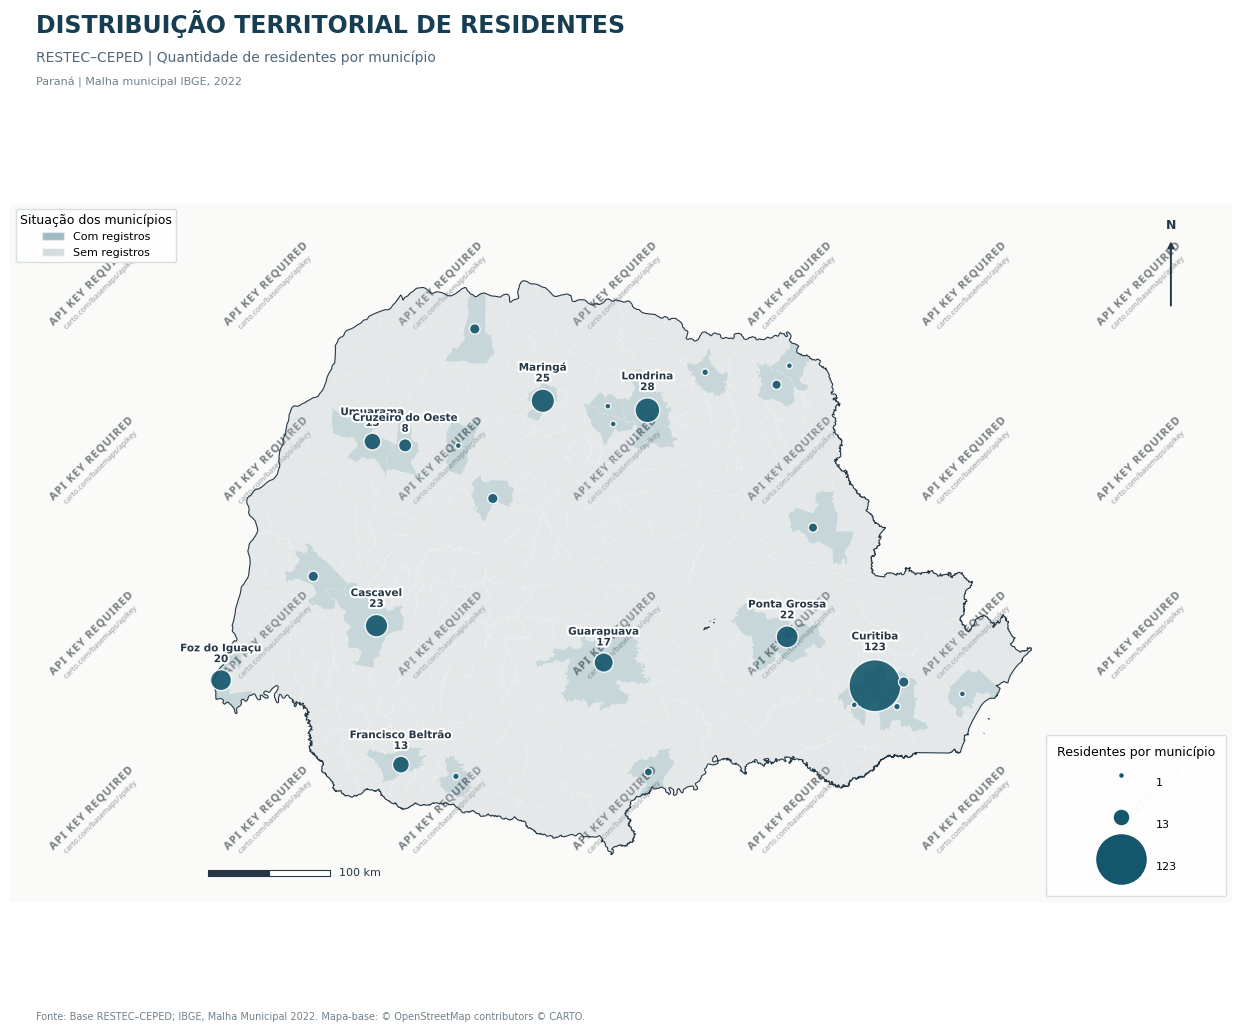

In [120]:
#Mapa geral de residentes

vmax_total = dados_total["residentes"].max()

fig, ax = plt.subplots(figsize=(13, 10.5))
fig.subplots_adjust(left=0.03, right=0.97, top=0.86, bottom=0.06)

desenhar_mapa(ax, dados_total, AZUL, vmax_total, area_max=1400, n_rotulos=10)

cabecalho(fig,
          "DISTRIBUIÇÃO TERRITORIAL DE RESIDENTES",
          "RESTEC–CEPED | Quantidade de residentes por município",
          "Paraná | Malha municipal IBGE, 2022")
rodape(fig)

fig.savefig(PASTA_SAIDA / "01_residentes.png", dpi=350, bbox_inches="tight")
plt.show()

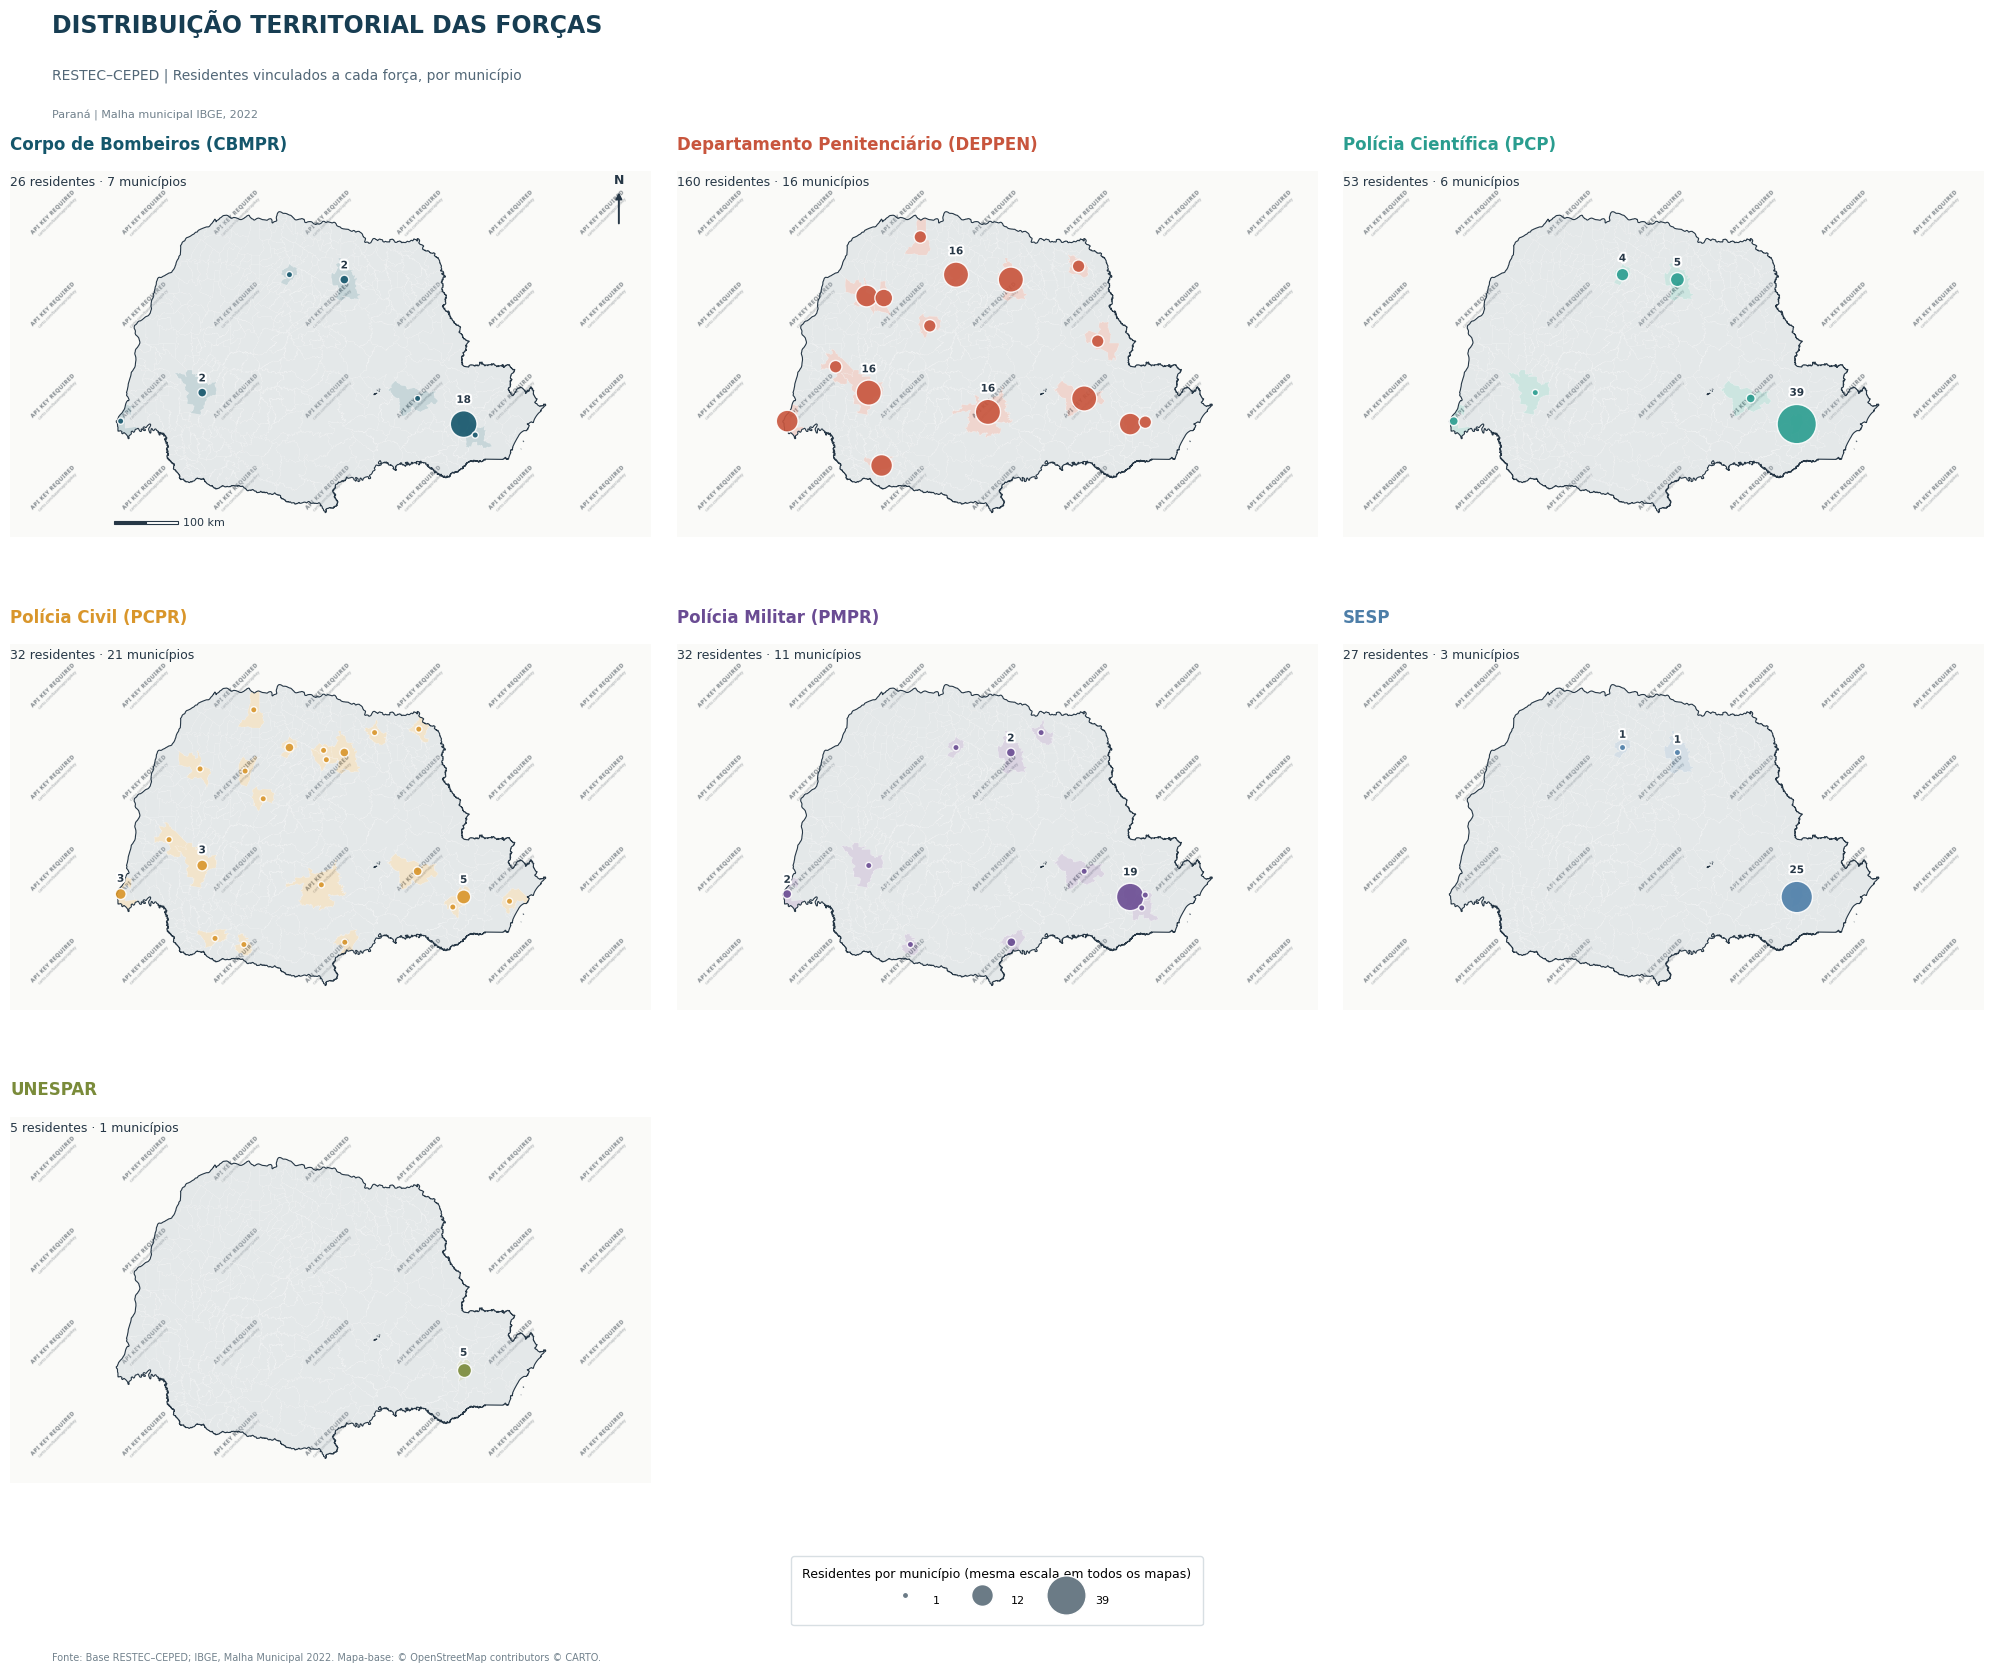

In [121]:
#Mapas por força (painéis comparáveis)

FORCAS = sorted(df["Forca"].unique())
N_COL = 3
N_LIN = int(np.ceil(len(FORCAS) / N_COL))
VMAX_FORCAS = forcas_mun["residentes"].max()   # mesma escala em todos os painéis
AREA_MAX = 800

fig, axes = plt.subplots(N_LIN, N_COL, figsize=(7 * N_COL, 5.2 * N_LIN + 1.5))
fig.subplots_adjust(left=0.03, right=0.97, top=0.89, bottom=0.09,
                    wspace=0.04, hspace=0.12)
axes = axes.ravel()

for i, (ax, forca) in enumerate(zip(axes, FORCAS)):
    d = dados_por_forca(forca)
    cor = PALETA_FORCAS[i % len(PALETA_FORCAS)]

    desenhar_mapa(ax, d, cor, VMAX_FORCAS, AREA_MAX, n_rotulos=3, nomes=False,
                  legendas=False, elementos=(i == 0))

    ax.set_title(forca, loc="left", fontsize=12, fontweight="bold",
                 color=cor, pad=6)
    ax.text(0.0, 0.99, f"{fmt(d['residentes'].sum())} residentes · {len(d)} municípios",
            transform=ax.transAxes, va="top", fontsize=9, color=COR_TEXTO)

for ax in axes[len(FORCAS):]:
    ax.remove()

# Legenda única de tamanho para todos os painéis
legenda_proporcional(fig, forcas_mun["residentes"], VMAX_FORCAS, AREA_MAX, "#6B7B86",
                     titulo="Residentes por município (mesma escala em todos os mapas)",
                     loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.02))

cabecalho(fig,
          "DISTRIBUIÇÃO TERRITORIAL DAS FORÇAS",
          "RESTEC–CEPED | Residentes vinculados a cada força, por município",
          "Paraná | Malha municipal IBGE, 2022")
fig.text(0.05, 0.003, FONTE, fontsize=7, color=COR_SUBTEXTO)

fig.savefig(PASTA_SAIDA / "02_mapas_forcas.png", dpi=300, bbox_inches="tight")
plt.show()